# HMDA 2024: Kết quả phân tích

Các ô dưới đây đọc kết quả đã tính trong `hmda_tables` (Spark), `hmda_pandas_checks` (Pandas và PyArrow) và `hmda_figures`. Mã nguồn nằm cùng thư mục. Cột kết thúc bằng `_pp` có đơn vị điểm phần trăm.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

pd.set_option('display.max_columns', 30)
here = Path.cwd()
tables = here / 'hmda_tables'
checks = here / 'hmda_pandas_checks'
figures = here / 'hmda_figures'

## 1. Dữ liệu, schema và chất lượng dữ liệu

In [2]:
raw = json.loads((checks / 'raw_audit_pyarrow.json').read_text())
print(f"{raw['file']}: {raw['bytes']:,} byte, {raw['records']:,} bản ghi, {raw['columns']} cột")
display(pd.read_csv(tables / 'waterfall.csv'))
display(pd.read_csv(checks / 'raw_schema_profile.csv').head(20))

2024_public_lar_one_year_csv.csv: 4,636,628,799 byte, 12,259,199 bản ghi, 99 cột


,step,n
0,input,12259199
1,year,12259199
2,action,6558317
3,purpose,3695167
4,lien,3553054
5,dwelling,3358918
6,occupancy,2945250
7,closed_end,2867963
8,non_reverse,2867757


,column,position,blank,na,exempt,numeric,other,other_examples
0,activity_year,1,0,0,0,12259199,0,NaN
1,lei,2,0,0,0,0,12259199,254900HA4DQWAE0W3342; 54930039UO39UJGI7078; 54...
2,derived_msa_md,3,0,0,0,12259199,0,NaN
3,state_code,4,0,215946,0,0,12043253,IL; OH; TN; TX; WA
4,county_code,5,0,296190,0,11963009,0,NaN
5,census_tract,6,0,349024,0,11910175,0,NaN
6,conforming_loan_limit,7,0,43570,0,0,12215629,C; NC
7,derived_loan_product_type,8,0,0,0,0,12259199,Conventional:First Lien; Conventional:Subordin...
8,derived_dwelling_category,9,0,0,0,0,12259199,Single Family (1-4 Units):Manufactured; Single...
9,derived_ethnicity,10,0,0,0,0,12259199,Ethnicity Not Available; Hispanic or Latino; J...


outcome                                        1      2      All
variable                     status                             
combined_loan_to_value_ratio exempt           48      0       48
                             na            75590   6221    81811
                             valid       2702962  82936  2785898
county_code                  na             2261   2557     4818
                             valid       2776339  86600  2862939
debt_to_income_ratio         exempt           49      0       49
                             na            12463   4728    17191
                             valid       2766088  84429  2850517
derived_msa_md               code_99999   286848  12982   299830
                             valid       2491752  76175  2567927
income                       na            19108    539    19647
                             valid       2759492  88618  2848110
interest_rate                exempt           49      1       50
                             na              496   1919     2415
                             valid       2778055  87237  2865292
loan_amount                  valid       2778600  89157  2867757
loan_term                    exempt           37      0       37
                             na             2683    354     3037
                             valid       2775880  88803  2864683
rate_spread                  exempt          102      4      106
                             na            32333  13401    45734
                             valid       2746165  75752  2821917

outcome                                          1      2     All
variable                     check                               
combined_loan_to_value_ratio above_150       146.0   34.0   180.0
                             nonpositive       0.0    0.0     0.0
income                       above_10m       177.0    6.0   183.0
                             negative         66.0    2.0    68.0
                             zero           8808.0  288.0  9096.0
interest_rate                above_15          1.0    0.0     1.0
                             nonpositive     768.0   54.0   822.0
loan_amount                  above_5m        580.0   61.0   641.0
                             nonpositive       0.0    0.0     0.0
loan_term                    above_480         1.0    0.0     1.0
                             nonpositive       0.0    0.0     0.0
rate_spread                  above_10         38.0   11.0    49.0
                             below_minus_5  1544.0  108.0  1652.0

,rule,lenders,share_of_action2_records,share_of_missing_action2_spreads,share_of_unknown_dti_action2_records,price_coverage_action1_without,price_coverage_action2_without,non_origination_rate_without
0,non_origination_above_50pct,28,0.038494,0.091458,0.481498,0.988324,0.857929,0.029937
1,action2_price_coverage_below_50pct,51,0.145877,0.760015,0.080877,0.990926,0.957755,0.027741
2,action2_unknown_dti_above_50pct,14,0.047859,0.055576,0.877908,0.988311,0.850866,0.029793
3,any_rule,78,0.191998,0.794107,0.892976,0.990902,0.961687,0.026396


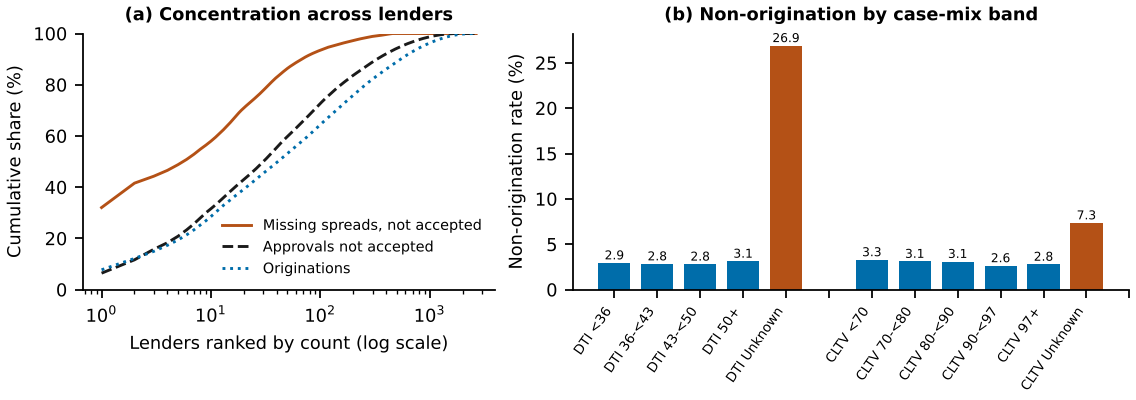

In [3]:
status = pd.read_csv(tables / 'profile_status_spark.csv', dtype={'outcome': str})
display(status.pivot_table(index=['variable', 'status'], columns='outcome', values='count').fillna(0).astype(int))
display(pd.read_csv(tables / 'profile_checks_spark.csv', dtype={'outcome': str}).pivot_table(index=['variable', 'check'], columns='outcome', values='count'))
display(pd.read_csv(tables / 'lender_reporting_audit.csv'))
display(Image(filename=str(figures / 'data_quality.png')))

## 2. Thống kê mô tả

,variable,outcome,n_records,n_valid,mean,sd,min,p01,p05,p25,p50,p75,p95,p99,max
0,combined_loan_to_value_ratio,1,2778600,2702962,84.644,16.932,0.10,26.066,48.000,80.000,90.000,96.500,100.000,102.564,9.018200e+02
1,combined_loan_to_value_ratio,2,89157,82936,83.273,18.354,1.03,22.830,43.711,78.947,90.000,96.500,100.240,104.505,7.466000e+02
2,combined_loan_to_value_ratio,All,2867757,2785898,84.603,16.978,0.10,26.000,47.917,80.000,90.000,96.500,100.000,102.634,9.018200e+02
3,income,1,2778600,2759492,153.668,344.638,-19288.00,30.000,46.000,78.000,114.000,172.000,360.000,728.000,2.240000e+05
4,income,2,89157,88618,165.531,303.066,-9.00,28.000,43.000,76.000,115.000,179.000,400.000,917.000,4.032300e+04
5,income,All,2867757,2848110,154.037,343.427,-19288.00,30.000,46.000,78.000,114.000,172.000,361.000,734.000,2.240000e+05
6,interest_rate,1,2778600,2778055,6.505,0.766,0.00,4.375,5.250,6.125,6.625,6.990,7.575,8.375,1.611600e+01
7,interest_rate,2,89157,87237,6.705,0.842,0.00,4.750,5.500,6.250,6.625,7.125,7.990,9.378,1.450000e+01
8,interest_rate,All,2867757,2865292,6.511,0.769,0.00,4.375,5.250,6.125,6.625,6.990,7.625,8.375,1.611600e+01
9,loan_amount,1,2778600,2778600,394252.177,304188.141,5000.00,75000.000,125000.000,225000.000,325000.000,475000.000,815000.000,1515000.000,2.500500e+07


,band,value,approvals,non_origination_rate,price_coverage_action2
0,amount_band,150000-<250000,610924,0.0304,0.8623
1,amount_band,250000-<400000,989479,0.0262,0.8525
2,amount_band,400000-<650000,699845,0.0297,0.8664
3,amount_band,650000+,316780,0.0368,0.8890
4,amount_band,<150000,245911,0.0392,0.8713
5,income_band,100-<150,753675,0.0285,0.8585
6,income_band,150-<250,595969,0.0305,0.8696
7,income_band,250+,329611,0.0353,0.8961
8,income_band,50-<100,983462,0.0286,0.8558
9,income_band,<50,180678,0.0366,0.8585


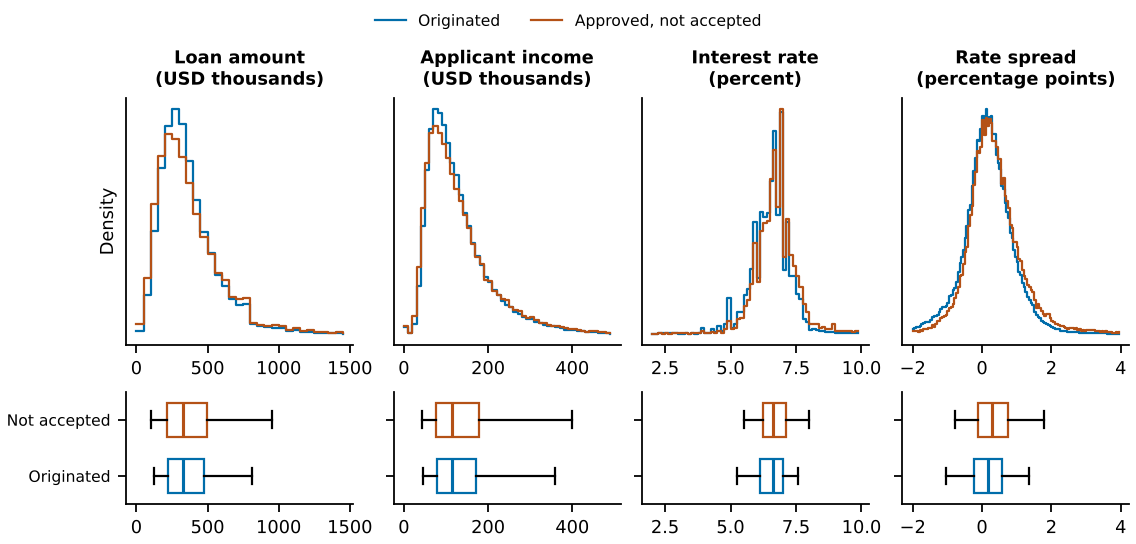

In [4]:
profile = pd.read_csv(tables / 'profile_numeric_spark.csv', dtype={'outcome': str})
display(profile.round(3))
display(pd.read_csv(tables / 'rates_by_band.csv').round(4))
display(Image(filename=str(figures / 'variable_distributions.png')))

## 3. Chênh lệch giá trong cùng segment

In [5]:
display(pd.read_csv(tables / 'matched_spark.csv').round(4))
display(pd.read_csv(tables / 'matched_by_amount_band_spark.csv').round(4))
display(pd.read_csv(tables / 'matched_composition.csv').round(3))

,geo,n_strata,n_originated_prices,n_fallout_prices,weighted_mean_of_median_gaps_pp,median_of_stratum_gaps_pp,share_strata_positive,rate_gap_on_same_segments_pp,scenario,all_valid_1,all_valid_2,share_valid_originated_prices_matched,share_valid_fallout_prices_matched
0,county,831,208780,17211,0.1107,0.0850,0.7100,0.1020,balanced_coverage,2744244,74904,0.0761,0.2298
1,county,829,208577,17189,0.1106,0.0840,0.7093,0.1019,both_coverage_80pct,2744244,74904,0.0760,0.2295
2,county,1009,234834,20531,0.0958,0.0625,0.5580,NaN,interest_rate_minimum_10_each,2744244,74904,0.0856,0.2741
3,county,857,215356,17647,0.1090,0.0810,0.7013,0.0995,minimum_10_prices_each,2744244,74904,0.0785,0.2356
4,msa,1120,417361,26523,0.1037,0.0745,0.6938,0.1016,balanced_coverage,2463617,65957,0.1694,0.4021
5,msa,1119,417133,26509,0.1035,0.0745,0.6935,0.1013,both_coverage_80pct,2463617,65957,0.1693,0.4019
6,msa,1352,462853,31980,0.0969,0.0625,0.5459,NaN,interest_rate_minimum_10_each,2463617,65957,0.1879,0.4849
7,msa,1177,434433,27538,0.1016,0.0720,0.6865,0.0983,minimum_10_prices_each,2463617,65957,0.1763,0.4175


,geo,amount_band,n_strata,n_originated_prices,n_fallout_prices,weighted_mean_of_median_gaps_pp,median_of_stratum_gaps_pp,share_strata_positive,rate_gap_on_same_segments_pp,scenario,all_valid_1,all_valid_2,share_valid_originated_prices_matched,share_valid_fallout_prices_matched
0,county,150000-<250000,50,6391,695,0.0755,0.0617,0.6200,0.0952,balanced_coverage,584940,16031,0.0109,0.0434
1,county,150000-<250000,50,6391,695,0.0755,0.0617,0.6200,0.0952,both_coverage_80pct,584940,16031,0.0109,0.0434
2,county,150000-<250000,63,7209,895,0.0895,0.0625,0.5556,NaN,interest_rate_minimum_10_each,584940,16031,0.0123,0.0558
3,county,150000-<250000,51,6465,707,0.0832,0.0655,0.6275,0.0946,minimum_10_prices_each,584940,16031,0.0111,0.0441
4,county,250000-<400000,106,18398,1569,0.0712,0.0635,0.6698,0.0756,balanced_coverage,952722,22126,0.0193,0.0709
5,county,250000-<400000,106,18398,1569,0.0712,0.0635,0.6698,0.0756,both_coverage_80pct,952722,22126,0.0193,0.0709
6,county,250000-<400000,122,20228,1818,0.0698,0.0625,0.5492,NaN,interest_rate_minimum_10_each,952722,22126,0.0212,0.0822
7,county,250000-<400000,106,18398,1569,0.0712,0.0635,0.6698,0.0756,minimum_10_prices_each,952722,22126,0.0193,0.0709
8,county,400000-<650000,132,20668,2450,0.1259,0.0970,0.6439,0.1153,balanced_coverage,672295,17978,0.0307,0.1363
9,county,400000-<650000,132,20668,2450,0.1259,0.0970,0.6439,0.1153,both_coverage_80pct,672295,17978,0.0307,0.1363


,band,value,share_originated,share_not_accepted
0,amount_band,150000-<250000,0.163,0.152
1,amount_band,250000-<400000,0.294,0.249
2,amount_band,400000-<650000,0.283,0.287
3,amount_band,650000+,0.201,0.243
4,amount_band,<150000,0.059,0.069
5,income_band,100-<150,0.248,0.237
6,income_band,150-<250,0.250,0.260
7,income_band,250+,0.185,0.221
8,income_band,50-<100,0.268,0.232
9,income_band,<50,0.040,0.043


## 4. So sánh với peers và mô hình

In [6]:
display(pd.read_csv(tables / 'robustness.csv').query("loan_type == 'All'"))
display(pd.read_csv(tables / 'sensitivity_summary.csv').round(4))
display(pd.read_csv(tables / 'flag_null.csv').T)
display(pd.read_csv(tables / 'price_model.csv'))

,scenario,geo,loan_type,eligible_segments,high_price_high_fallout,primary_candidates,primary_still_eligible,primary_retained
0,primary,msa,All,3780,558,558,558,558
1,primary,county,All,3033,404,404,404,404
10,minimum_volume_50,msa,All,4902,778,558,558,558
11,minimum_volume_50,county,All,4261,640,404,404,404
20,minimum_volume_200,msa,All,2028,251,558,251,251
21,minimum_volume_200,county,All,1362,146,404,146,146
30,reference_support_80pct,msa,All,1262,206,558,206,206
31,reference_support_80pct,county,All,879,124,404,124,124
40,originated_price_coverage_80pct,msa,All,3771,558,558,558,558
41,originated_price_coverage_80pct,county,All,3030,403,404,403,403


,scenario,geo,eligible_segments,flags,spearman,matched_segments,matched_gap_bp,share_positive
0,baseline,county,3033,404,0.0454,857,10.8951,0.7001
1,baseline,msa,3780,558,0.0731,1177,10.1589,0.6865
2,excluding_anomalous_reporters,county,2928,345,0.0146,802,10.6145,0.7020
3,excluding_anomalous_reporters,msa,3610,490,0.0450,1094,9.7305,0.6856
4,unknown_strata_unsupported,county,3033,404,0.0455,857,10.8951,0.7001
5,unknown_strata_unsupported,msa,3777,558,0.0743,1177,10.1589,0.6865


,0,1
geo,county,msa
eligible_segments,3033,3780
observed_flags,404,558
share_price_gap_positive,0.540719,0.54709
share_adjusted_gap_positive,0.216288,0.233598
expected_flags_if_independent,354.711507,483.080423
permutation_mean,356.0685,482.956
permutation_sd,11.320198,12.937649
permutation_p_value,0.0005,0.0005
flags_with_fallout_z_above_1_96,288,423


,specification,n_identifying_records,fixed_effect_strata,lender_clusters,fallout_pp_per_spread_pp,lender_clustered_se_pp,ci95_lower_pp,ci95_upper_pp,trim_lower_spread_pp,trim_upper_spread_pp,approx_lower_spread_pp,approx_upper_spread_pp
0,lender_county_product,2650309,184450,2384,0.098347,0.085631,-0.069490,0.266183,NaN,NaN,NaN,NaN
1,lender_county_product_on_case_mix_sample,1377846,66890,2032,0.430569,0.135025,0.165920,0.695218,NaN,NaN,NaN,NaN
2,lender_county_product_case_mix,1377846,384947,2032,0.437910,0.164389,0.115708,0.760112,NaN,NaN,NaN,NaN
3,balanced_price_coverage_case_mix,197016,32445,155,1.605438,0.532315,0.562101,2.648775,NaN,NaN,NaN,NaN
4,central_98_percent_price_case_mix,1345236,377434,2009,0.639527,0.162379,0.321264,0.957790,-1.805,2.186,-1.804,2.186


## 5. Đối chiếu Pandas và PySpark

In [7]:
correct = pd.read_csv(tables / 'correctness_table.csv')
print(correct['agreement'].str.split(' ').str[0].value_counts())
display(correct)

agreement
Exact     90
Within    14
Single     1
Name: count, dtype: int64


,section,quantity,pandas,spark,agreement,note
0,Data preparation,Records after filter step 'input',12259199,12259199,Exact,"Pandas side reads the raw CSV with PyArrow, in..."
1,Data preparation,Records after filter step 'year',12259199,12259199,Exact,"Pandas side reads the raw CSV with PyArrow, in..."
2,Data preparation,Records after filter step 'action',6558317,6558317,Exact,"Pandas side reads the raw CSV with PyArrow, in..."
3,Data preparation,Records after filter step 'purpose',3695167,3695167,Exact,"Pandas side reads the raw CSV with PyArrow, in..."
4,Data preparation,Records after filter step 'lien',3553054,3553054,Exact,"Pandas side reads the raw CSV with PyArrow, in..."
...,...,...,...,...,...,...
100,Price model,central_98_percent_price_case_mix: lender clus...,2009,2009,Exact,NaN
101,Price model,central_98_percent_price_case_mix: coefficient...,0.6395269479456602,0.6395269479456602,Exact,NaN
102,Price model,central_98_percent_price_case_mix: clustered SE,0.1623791559078894,0.1623791559078893,Within tolerance (|diff| = 1.1e-16),NaN
103,Price model,central_98: trim_lower_spread_pp,-1.805,-1.805,Exact,Both exact (inverted CDF / percentile_disc); t...


## 6. Benchmark

,size_pct,input_rows,pandas_median_s,pandas_min_s,pandas_max_s,spark_uncached_median_s,spark_uncached_min_s,spark_uncached_max_s,spark_cached_median_s,spark_cache_build_median_s,speedup_pandas_over_spark_uncached,faster,pandas_process_peak_rss_mib,spark_cache_memory_mib,spark_cache_disk_mib
0,25,3066854,0.616,0.609,0.624,0.452,0.393,0.737,0.343,0.968,1.362,Spark,942.109,23.668,0.0
1,50,6131223,1.425,1.235,1.679,0.422,0.416,0.610,0.528,1.708,3.377,Spark,1570.734,47.312,0.0
2,100,12259199,2.578,2.542,2.602,0.638,0.632,0.662,0.837,3.256,4.038,Spark,2331.406,94.635,0.0


status                                                                                passed
waterfall_steps                                                                            9
groups_compared                                                                       360342
cohort_records                                                                       2867757
group_count_fields_exact                                       [n, n_fallout, n_price_valid]
float_fields                                           [rate, spread_mean, q25, median, q75]
float_absolute_tolerance                                                                 0.0
float_relative_tolerance                                                                 0.0
max_abs_differences                        {'rate': 0.0, 'spread_mean': 1.77635683940025e...
benchmark_repeated_checks                                                                 30
benchmark_spread_sum_absolute_tolerance                               

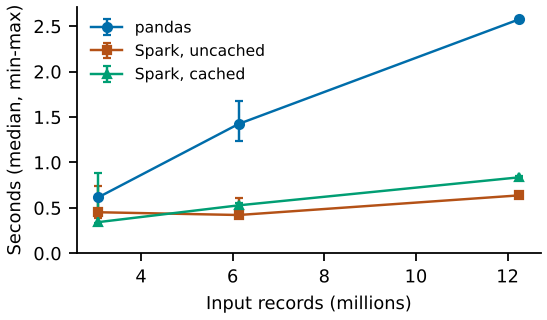

In [8]:
display(pd.read_csv(tables / 'benchmark_table.csv').round(3))
display(pd.read_json(tables / 'engine_agreement.json', typ='series'))
display(Image(filename=str(figures / 'benchmark_scaling.png')))

## 7. Hồ sơ mã 1111 bị loại khỏi cohort

Hai bộ lọc cuối (khoản vay đóng, không phải vay đảo ngược) loại các hồ sơ mang mã 1111 của tổ chức dùng quyền miễn trừ một phần. Bảng dưới so sánh nhóm này với nhóm được giữ.

In [9]:
display(pd.read_csv(tables / 'exempt_audit.csv'))

,group,records,lenders,share_not_accepted,median_records_per_lender,share_price_reported_exempt,records_before_filters,lenders_only_exempt,lenders_in_both
0,kept in cohort,2867757,2656,0.031089,125.0,0.000037,2945250,1828,38
1,exempt code (1111),61371,1866,0.052060,20.0,0.988545,2945250,1828,38
2,open-end or reverse,16122,658,0.081255,7.0,0.000000,2945250,1828,38


## 8. Phần mở rộng dự đoán rate spread

Kế hoạch phân tích được viết và băm trước khi chạy (`predictive_plan.md`). Các bảng dưới gồm chỉ số dự đoán ngoài fold, chênh thô và chênh phần dư trong phân khúc, đối chiếu hai engine và kết luận theo quy tắc đặt trước.

In [10]:
decision = json.loads((tables / 'predict_decision.json').read_text())
print('Quy tắc kết luận:', decision['rule'])
print(f"Chênh thô {decision['raw_gap_bp']:.1f} bp, chênh phần dư {decision['resid_gap_bp']:.1f} bp, phần được giải thích {decision['share_explained']:.1%}")
display(pd.read_csv(tables / 'predict_metrics.csv').round(4))
display(pd.read_csv(tables / 'predict_matched.csv').round(3))
agree = pd.read_csv(tables / 'predict_agreement.csv')
print(agree.groupby('output')['agree'].all())

Quy tắc kết luận: persists
Chênh thô 10.1 bp, chênh phần dư 9.7 bp, phần được giải thích 4.4%


,variant,model,n,sse,sae,rmse_bp,mae_bp,r2,r2_vs_M0,r2_within_vs_M1
0,main,M0,2601028,1.030097e+06,1.243074e+06,62.9313,47.7917,0.0809,0.0000,NaN
1,main,M1,2601028,7.084556e+05,1.041854e+06,52.1896,40.0555,0.3679,0.3122,NaN
2,main,M2,2601028,6.270852e+05,9.731885e+05,49.1010,37.4155,0.4405,0.3912,0.1149
3,unknown_core,M0,2689436,1.060170e+06,1.284201e+06,62.7852,47.7498,0.0808,0.0000,NaN
4,unknown_core,M1,2689436,7.312941e+05,1.077311e+06,52.1453,40.0572,0.3659,0.3102,NaN
5,unknown_core,M2,2689436,6.504559e+05,1.009147e+06,49.1788,37.5226,0.4360,0.3865,0.1105
6,main,M3,2601028,5.981485e+05,9.531333e+05,47.9548,36.6445,0.4663,0.4193,0.1557


,variant,amount_band,n_segments,n_originated,n_not_accepted,raw_gap_bp,raw_lo_bp,raw_hi_bp,resid_gap_bp,resid_lo_bp,resid_hi_bp,share_explained,share_lo,share_hi,share_segments_resid_positive
0,central_98,All,767,199119,15606,8.680,7.460,9.956,8.617,7.391,9.979,0.007,-0.080,0.088,0.688
1,gbt,All,788,205214,16226,10.112,8.288,12.092,9.245,7.391,11.178,0.086,0.011,0.157,0.694
2,main,All,788,205214,16226,10.112,8.288,12.092,9.667,7.871,11.551,0.044,-0.039,0.118,0.703
3,main_by_amount_band,150000-<250000,51,6434,705,8.423,3.398,13.530,6.430,0.578,11.810,0.237,-0.259,0.864,0.667
4,main_by_amount_band,250000-<400000,94,17668,1406,6.766,2.642,10.788,6.590,3.166,9.995,0.026,-0.554,0.334,0.638
5,main_by_amount_band,400000-<650000,122,20008,2235,10.844,6.874,15.192,10.552,6.808,14.849,0.027,-0.141,0.168,0.680
6,main_by_amount_band,650000+,110,18847,2370,11.524,8.082,14.823,10.645,7.262,13.934,0.076,-0.064,0.224,0.700
7,main_by_amount_band,<150000,15,1285,202,205.500,9.979,399.391,195.842,3.900,387.259,0.047,0.020,0.570,0.667
8,support,All,763,204828,15874,9.955,8.098,12.009,9.518,7.730,11.504,0.044,-0.037,0.118,0.699
9,unknown_core,All,857,215356,17647,10.895,9.356,12.439,8.579,6.959,10.165,0.213,0.125,0.310,0.683


output
coefficients          True
matched gaps          True
metadata              True
prediction metrics    True
reporting audit       True
segment medians       True
Name: agree, dtype: bool


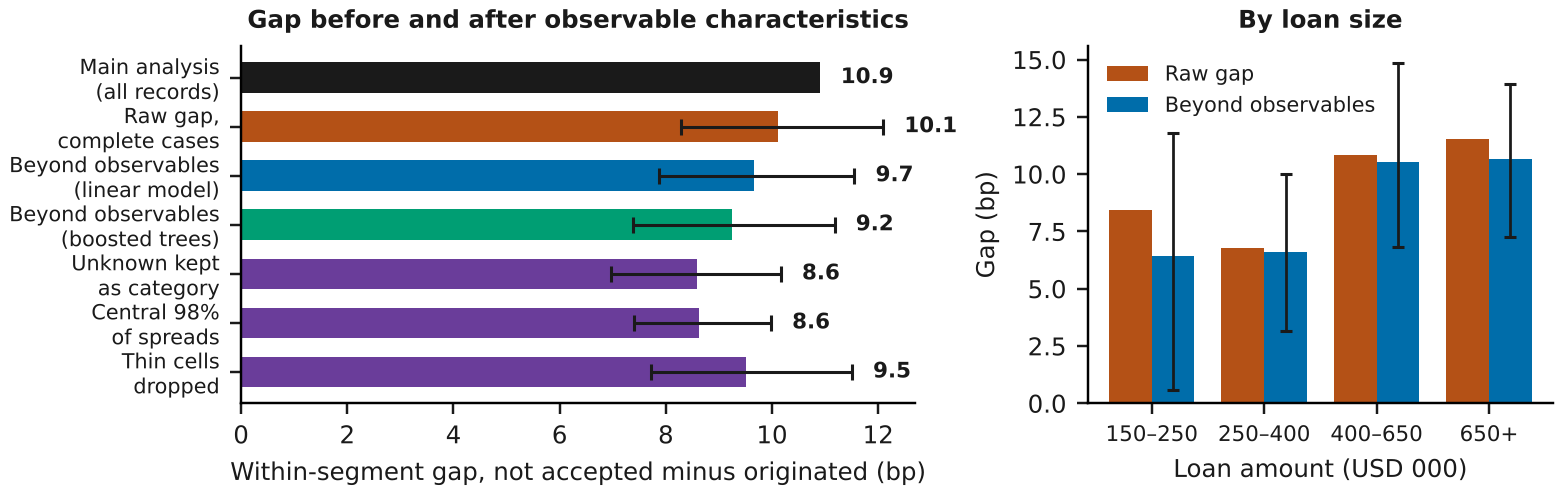

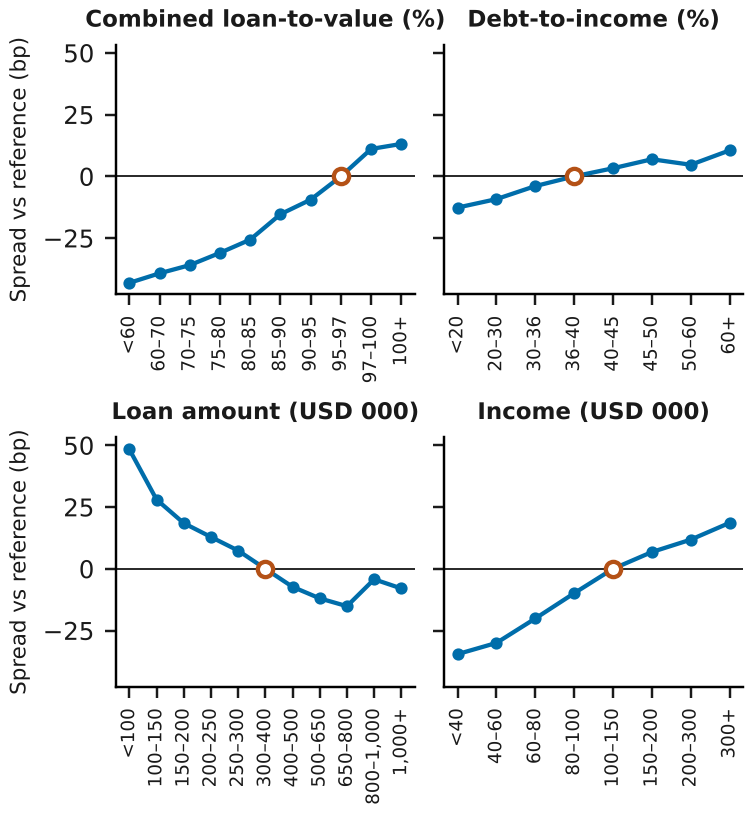

In [11]:
for name in ['predict_gap.png', 'predict_gradients.png']:
    display(Image(filename=str(figures / name)))

## 9. Đọc CSV bằng pandas thuần và địa lý theo bang

`hmda_pandas_csv.py` đọc file CSV gốc bằng `pandas.read_csv` (engine C, mọi cột dạng chuỗi, không PyArrow, không đọc Parquet của Spark), áp tám bộ lọc và dựng segment lender × quận × sản phẩm × kết quả. `hmda_geography.py` gộp segment theo bang (hai chữ số đầu của mã quận), so pandas với Spark và vẽ bản đồ.

In [12]:
print(json.loads((checks / 'pandas_csv_meta.json').read_text()))
w = pd.read_csv(tables / 'waterfall.csv').merge(pd.read_csv(checks / 'waterfall_pandas_csv.csv'), on='step', suffixes=('_spark', '_pandas_read_csv'))
display(w)
display(pd.read_csv(tables / 'geography_agreement.csv'))
print(json.loads((tables / 'geography_summary.json').read_text()))

{'reader': "pandas 2.3.3 read_csv(engine='c', dtype=str, chunksize=400000)", 'python': '3.10.12', 'rows_read': 12259199, 'cohort': 2867757, 'read_and_filter_seconds': 4.6, 'total_seconds': 5.9, 'parts': 8, 'part_read_seconds_sum': 59.7, 'note': 'parts read in separate processes (byte ranges, 180 s device limit); read_and_filter_seconds covers the combine step only', 'peak_rss_mib': 893.4}


,step,n_spark,n_pandas_read_csv
0,input,12259199,12259199
1,year,12259199,12259199
2,action,6558317,6558317
3,purpose,3695167,3695167
4,lien,3553054,3553054
5,dwelling,3358918,3358918
6,occupancy,2945250,2945250
7,closed_end,2867963,2867963
8,non_reverse,2867757,2867757


,table,quantity,rows_compared,max_abs_diff,agree
0,county segments,rows only in one engine,0,0.000000e+00,True
1,county segments,n,392316,0.000000e+00,True
2,county segments,n_price_valid,392316,0.000000e+00,True
3,county segments,median,382505,7.105427e-15,True
4,state geography,rows only in one engine,0,0.000000e+00,True
5,state geography,n,54,0.000000e+00,True
6,state geography,n_fallout,54,0.000000e+00,True
7,state geography,rate_pct,54,0.000000e+00,True
8,state geography,top_lender_share_pct,53,0.000000e+00,True
9,state geography,rate_without_top_lender_pct,53,0.000000e+00,True


{'states_with_counties': 54, 'records_with_county': 2862939, 'national_matched_gap_bp': 10.895, 'matched_segments': 857, 'spearman_rate_vs_top_lender_share_2000plus': 0.142, 'all_agree': True}


,state_fips,abbr,n,n_fallout,rate_pct,lenders_with_fallout,top_lender_share_pct,rate_without_top_lender_pct,top3_lender_share_pct,matched_segments,gap_bp
3,05,AR,27131,2091,7.71,123.0,66.67,2.71,70.40,1,-26.15
12,16,ID,21297,1109,5.21,90.0,42.29,3.42,59.87,12,6.17
37,41,OR,35665,1481,4.15,131.0,22.08,3.54,38.49,18,13.57
42,47,TN,69373,2767,3.99,228.0,11.78,3.54,27.18,12,11.03
48,54,WV,12485,495,3.96,81.0,22.02,3.29,41.01,1,13.30
28,32,NV,33559,1326,3.95,122.0,14.71,3.68,33.48,25,13.64
31,35,NM,16447,644,3.92,88.0,20.50,3.40,36.80,4,0.77
5,08,CO,68052,2604,3.83,184.0,15.17,3.33,33.33,42,11.98
36,40,OK,34646,1312,3.79,141.0,13.49,3.38,27.36,9,-2.27
24,28,MS,19487,736,3.78,94.0,9.51,3.54,23.78,2,1.20


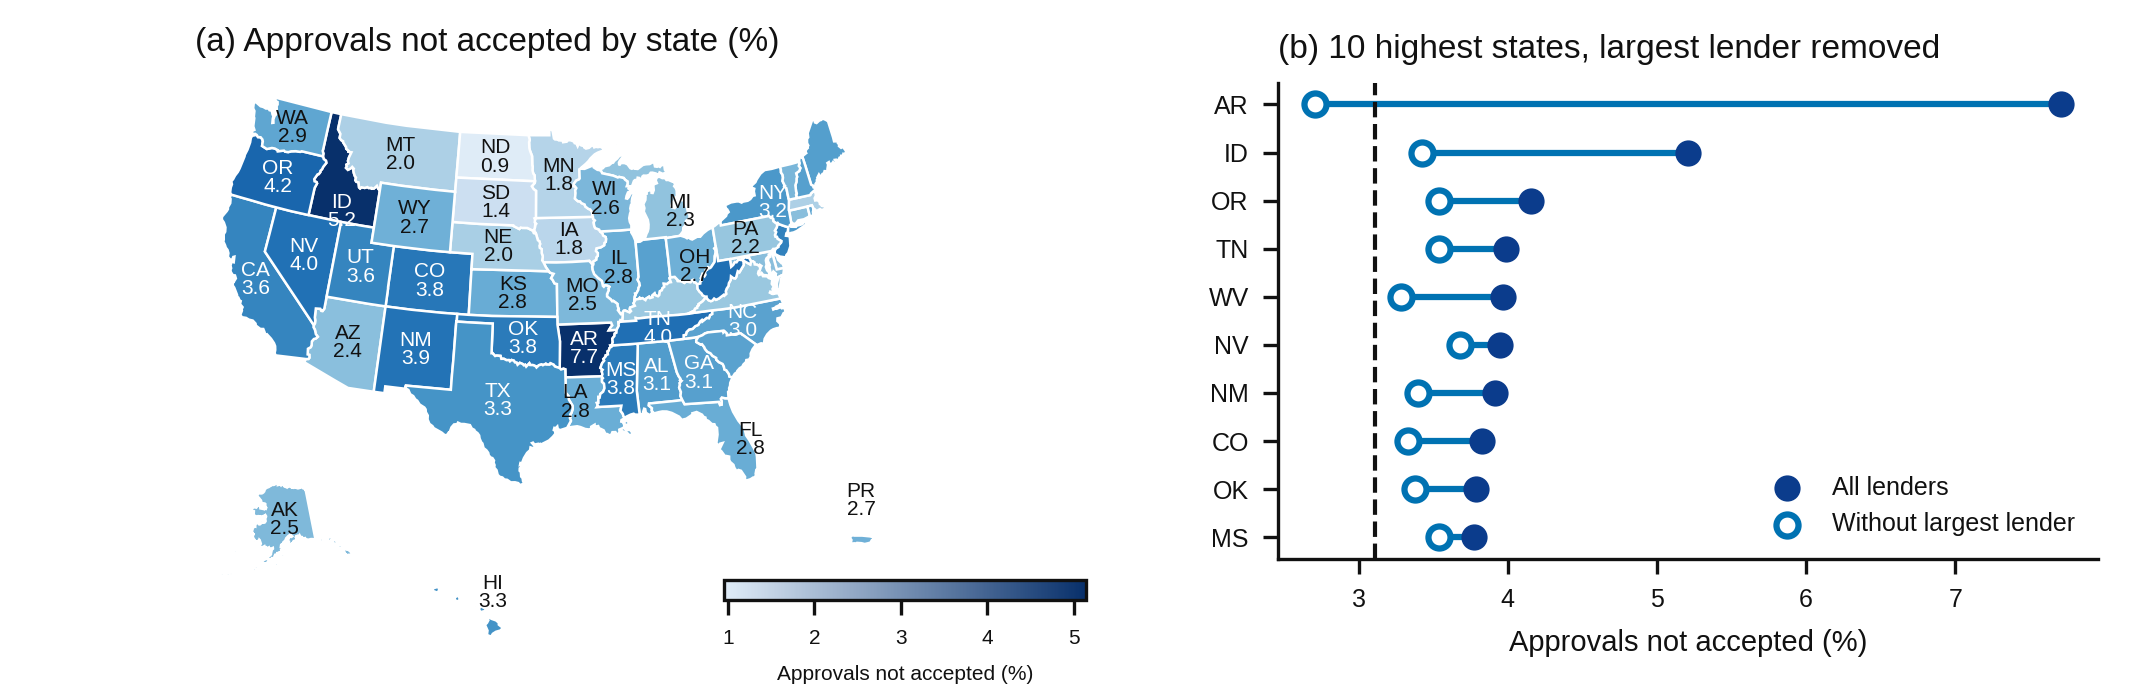

In [13]:
geo = pd.read_csv(tables / 'geography_state.csv', dtype={'state_fips': str})
display(geo.sort_values('rate_pct', ascending=False).head(10).round(2))
display(Image(filename=str(figures / 'geography_states.png')))

## Tái lập phân tích

Trong Terminal, chạy tại thư mục chứa notebook, trong môi trường `hmda-spark`:

    bash reproduce.sh ~/Downloads/2024_public_lar_one_year_csv.csv

Mỗi lần chạy tạo một thư mục kết quả mới. Hướng dẫn cài đặt, nguồn dữ liệu và SHA-256 của tệp gốc nằm trong README ở thư mục cha.